# ⚛️ Hybrid Quantum Machine Learning for Financial Data
### Qiskit Fall Fest Workshop • Beginner to Intermediate Track

Welcome! In this interactive notebook, we build **Hybrid Quantum-Classical Neural Networks** by connecting **Qiskit** quantum circuits directly into **PyTorch** using `TorchConnector`.

---

### 🗺️ Presentation Roadmap
1. **Setup & Modern Qiskit 2.x Stack** — Primitives (`StatevectorEstimator` & `StatevectorSampler`) and functional circuit builders.
2. **Part 1.1: Loan Approval Classification with `EstimatorQNN`** — Predicting continuous expectation values $\langle Z^{\otimes n} \rangle \in [-1, 1]$.
3. **Part 1.2: Loan Approval Classification with `SamplerQNN`** — Sampling measurement bitstrings and mapping parity to class probabilities.
4. **Part 2: Financial Yield Curve Regression with `EstimatorQNN`** — Learning a smooth non-linear function $y = \sin(x)$ with a single qubit.

---

### 🧠 Visual Guide: How a Hybrid Quantum-Classical Neural Network Works

<div align="center">
<svg width="820" height="230" viewBox="0 0 820 230" xmlns="http://www.w3.org/2000/svg">
  <defs>
    <marker id="arrow" viewBox="0 0 10 10" refX="8" refY="5" markerWidth="6" markerHeight="6" orient="auto-start-reverse">
      <path d="M 0 1 L 10 5 L 0 9 z" fill="#4f46e5"/>
    </marker>
    <marker id="arrow-red" viewBox="0 0 10 10" refX="8" refY="5" markerWidth="6" markerHeight="6" orient="auto-start-reverse">
      <path d="M 0 1 L 10 5 L 0 9 z" fill="#e11d48"/>
    </marker>
  </defs>

  <!-- Background Card -->
  <rect x="5" y="5" width="810" height="220" rx="14" fill="#f8fafc" stroke="#cbd5e1" stroke-width="1.5"/>

  <!-- Box 1: Classical Data -->
  <rect x="25" y="45" width="145" height="90" rx="10" fill="#e0e7ff" stroke="#4f46e5" stroke-width="2"/>
  <text x="97" y="75" font-family="sans-serif" font-size="13" font-weight="bold" fill="#1e1b4b" text-anchor="middle">1. Classical Data</text>
  <text x="97" y="96" font-family="sans-serif" font-size="11" fill="#312e81" text-anchor="middle">Customer Features</text>
  <text x="97" y="114" font-family="monospace" font-size="11" fill="#4338ca" text-anchor="middle">x = [Age, Income]</text>

  <!-- Arrow 1->2 -->
  <line x1="170" y1="90" x2="205" y2="90" stroke="#4f46e5" stroke-width="2" marker-end="url(#arrow)"/>

  <!-- Box 2: Feature Map -->
  <rect x="210" y="45" width="155" height="90" rx="10" fill="#dbeafe" stroke="#2563eb" stroke-width="2"/>
  <text x="287" y="75" font-family="sans-serif" font-size="13" font-weight="bold" fill="#1e3a8a" text-anchor="middle">2. Feature Map U(x)</text>
  <text x="287" y="96" font-family="sans-serif" font-size="11" fill="#1e40af" text-anchor="middle">Encodes data into</text>
  <text x="287" y="114" font-family="sans-serif" font-size="11" fill="#1e40af" text-anchor="middle">Hilbert space (ZZ)</text>

  <!-- Arrow 2->3 -->
  <line x1="365" y1="90" x2="400" y2="90" stroke="#4f46e5" stroke-width="2" marker-end="url(#arrow)"/>

  <!-- Box 3: Variational Ansatz -->
  <rect x="405" y="45" width="165" height="90" rx="10" fill="#ede9fe" stroke="#7c3aed" stroke-width="2"/>
  <text x="487" y="75" font-family="sans-serif" font-size="13" font-weight="bold" fill="#4c1d95" text-anchor="middle">3. Ansatz W(θ)</text>
  <text x="487" y="96" font-family="sans-serif" font-size="11" fill="#5b21b6" text-anchor="middle">Trainable rotation gates</text>
  <text x="487" y="114" font-family="monospace" font-size="11" fill="#6d28d9" text-anchor="middle">Weights θ (RealAmp)</text>

  <!-- Arrow 3->4 -->
  <line x1="570" y1="90" x2="605" y2="90" stroke="#4f46e5" stroke-width="2" marker-end="url(#arrow)"/>

  <!-- Box 4: Measurement & PyTorch -->
  <rect x="610" y="45" width="180" height="90" rx="10" fill="#dcfce7" stroke="#16a34a" stroke-width="2"/>
  <text x="700" y="75" font-family="sans-serif" font-size="13" font-weight="bold" fill="#14532d" text-anchor="middle">4. Measure &amp; Loss</text>
  <text x="700" y="96" font-family="sans-serif" font-size="11" fill="#166534" text-anchor="middle">Estimator / Sampler</text>
  <text x="700" y="114" font-family="sans-serif" font-size="11" fill="#15803d" text-anchor="middle">PyTorch Loss L(ŷ, y)</text>

  <!-- Backward Pass Loop -->
  <path d="M 700 135 L 700 185 L 487 185 L 487 140" fill="none" stroke="#e11d48" stroke-width="2" stroke-dasharray="6,4" marker-end="url(#arrow-red)"/>
  <rect x="495" y="168" width="200" height="26" rx="6" fill="#ffe4e6" stroke="#e11d48" stroke-width="1"/>
  <text x="595" y="185" font-family="sans-serif" font-size="11" font-weight="bold" fill="#9f1239" text-anchor="middle">PyTorch Autograd + Parameter-Shift ∇θ</text>
</svg>
</div>

In [ ]:
# Install the latest Qiskit (v2.6+) and Qiskit Machine Learning (v0.9.1+) with PyTorch support
!pip install -q "qiskit>=2.0" "qiskit-machine-learning[torch]>=0.9.1" "matplotlib>=3.8" "pylatexenc"

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import torch
from torch import Tensor
from torch.nn import MSELoss, CrossEntropyLoss
from torch.optim import LBFGS

import qiskit
import qiskit_machine_learning
from qiskit import QuantumCircuit
from qiskit.circuit.library import zz_feature_map, real_amplitudes
from qiskit.primitives import StatevectorEstimator, StatevectorSampler

from qiskit_machine_learning.utils import algorithm_globals
from qiskit_machine_learning.neural_networks import EstimatorQNN, SamplerQNN
from qiskit_machine_learning.gradients import (
    ParamShiftEstimatorGradient,
    ParamShiftSamplerGradient,
)
from qiskit_machine_learning.connectors import TorchConnector

# Fix random seeds for reproducible workshop results
algorithm_globals.random_seed = 42
torch.manual_seed(42)
np.random.seed(42)

print(f"Qiskit SDK version              : {qiskit.__version__}")
print(f"Qiskit Machine Learning version : {qiskit_machine_learning.__version__}")
print(f"PyTorch version                 : {torch.__version__}")

Qiskit SDK version              : 2.6.2
Qiskit Machine Learning version : 0.9.1
PyTorch version                 : 2.14.1+cpu


# 1. Classification: Financial Loan Approval

### 💡 Problem Statement
Suppose a bank wants to automate initial credit screening for **20 loan applicants** using two financial indicators:
* **Feature 1 ($x_0$):** Customer Age (scaled to $[-1, 1]$, representing ages $20\text{–}70$)
* **Feature 2 ($x_1$):** Annual Income (scaled to $[-1, 1]$, representing $\$20\text{k–}\$120\text{k}$)

> **Why scale features to $[-1, 1]$?**  
> Quantum feature maps encode classical numbers as **qubit rotation angles** (in radians). Scaling features into $[-1, 1]$ or $[-\pi, \pi]$ prevents wrap-around aliasing ($2\pi$ periodicity) on the Bloch sphere.

### 🎯 Target Labels
* **Approve Loan ($+1$ / Class `1`):** Customers where $x_0 + x_1 \ge 0$ (strong combined age/career stability and income).
* **Reject Loan ($-1$ / Class `0`):** Customers where $x_0 + x_1 < 0$.

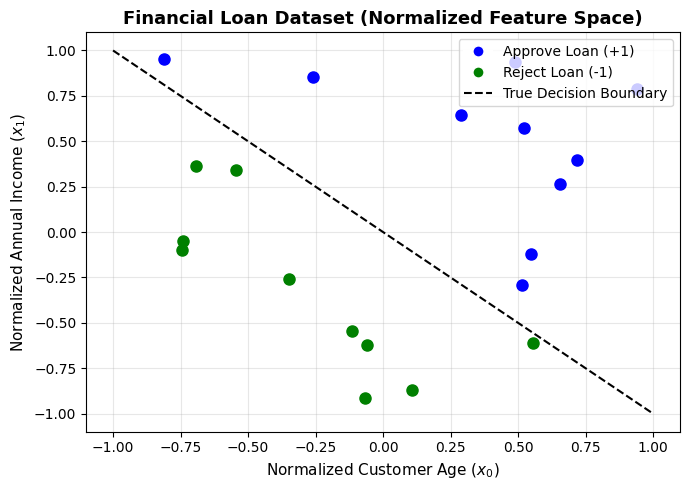

In [ ]:
# Select dataset dimension (num_inputs) and size (num_samples)
num_inputs = 2
num_samples = 20

# Generate normalized financial features X in [-1, 1]^2:
# Column 0 -> Normalized Customer Age
# Column 1 -> Normalized Annual Income
X = 2 * algorithm_globals.random.random([num_samples, num_inputs]) - 1

# Binary labels:
# y01 in {0, 1}  -> used for SamplerQNN + CrossEntropyLoss
# y   in {-1, +1} -> used for EstimatorQNN + MSELoss
y01 = 1 * (np.sum(X, axis=1) >= 0)
y = 2 * y01 - 1

# Convert NumPy arrays to PyTorch Tensors
X_ = Tensor(X)
y01_ = Tensor(y01).long()
y_ = Tensor(y).reshape(len(y), 1)

# Visualize the Financial Loan Dataset
plt.figure(figsize=(7, 5))
for x_pt, y_target in zip(X, y):
    if y_target == 1:
        plt.plot(x_pt[0], x_pt[1], "bo", markersize=8)
    else:
        plt.plot(x_pt[0], x_pt[1], "go", markersize=8)

# Plot true linear decision boundary (x0 + x1 = 0)
plt.plot([-1, 1], [1, -1], "--", color="black", linewidth=1.5)

legend_elements = [
    Line2D([0], [0], marker="o", color="w", label="Approve Loan (+1)", markerfacecolor="b", markersize=8),
    Line2D([0], [0], marker="o", color="w", label="Reject Loan (-1)", markerfacecolor="g", markersize=8),
    Line2D([0], [0], color="black", linestyle="--", label="True Decision Boundary"),
]
plt.title("Financial Loan Dataset (Normalized Feature Space)", fontsize=13, fontweight="bold")
plt.xlabel("Normalized Customer Age ($x_0$)", fontsize=11)
plt.ylabel("Normalized Annual Income ($x_1$)", fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend(handles=legend_elements, loc="upper right")
plt.tight_layout()
plt.show()

# 1.1 Classification with PyTorch and `EstimatorQNN`

## Step 1: Map the Classical Problem to a Parameterized Quantum Circuit (PQC)

To process classical data on a quantum computer, we compose two standard building blocks from `qiskit.circuit.library`:

| Component | Qiskit 2.x Function | Role in QML | Parameters |
| :--- | :--- | :--- | :--- |
| **Feature Map** | `zz_feature_map(feature_dimension=2)` | Maps classical inputs $\mathbf{x} = (x_0, x_1)$ into entangled quantum states $\|\phi(\mathbf{x})\rangle$. | **Input parameters** (`x[0], x[1]`) — fixed per data point |
| **Variational Ansatz** | `real_amplitudes(num_qubits=2)` | Applies alternating $R_Y(\theta_i)$ rotations and `CX` entangling gates to learn a separating hyperplane in Hilbert space. | **Weight parameters** ($\boldsymbol{\theta}$) — updated by PyTorch |

<div align="center">
<svg width="760" height="150" viewBox="0 0 760 150" xmlns="http://www.w3.org/2000/svg">
  <rect x="5" y="5" width="750" height="140" rx="12" fill="#f8fafc" stroke="#cbd5e1" stroke-width="1.5"/>
  <!-- Qubit wires -->
  <text x="25" y="55" font-family="monospace" font-size="13" fill="#0f172a">|0⟩ ──</text>
  <text x="25" y="105" font-family="monospace" font-size="13" fill="#0f172a">|0⟩ ──</text>
  <line x1="75" y1="50" x2="660" y2="50" stroke="#64748b" stroke-width="2"/>
  <line x1="75" y1="100" x2="660" y2="100" stroke="#64748b" stroke-width="2"/>

  <!-- Feature Map Block -->
  <rect x="95" y="25" width="210" height="100" rx="8" fill="#dbeafe" stroke="#2563eb" stroke-width="2"/>
  <text x="200" y="68" font-family="sans-serif" font-size="13" font-weight="bold" fill="#1e3a8a" text-anchor="middle">ZZ Feature Map</text>
  <text x="200" y="90" font-family="monospace" font-size="11" fill="#1d4ed8" text-anchor="middle">U_Φ(x[0], x[1])</text>

  <!-- Barrier -->
  <line x1="335" y1="20" x2="335" y2="130" stroke="#94a3b8" stroke-width="2" stroke-dasharray="5,5"/>

  <!-- Ansatz Block -->
  <rect x="365" y="25" width="220" height="100" rx="8" fill="#ede9fe" stroke="#7c3aed" stroke-width="2"/>
  <text x="475" y="68" font-family="sans-serif" font-size="13" font-weight="bold" fill="#4c1d95" text-anchor="middle">RealAmplitudes Ansatz</text>
  <text x="475" y="90" font-family="monospace" font-size="11" fill="#6d28d9" text-anchor="middle">W(θ[0], ..., θ[7])</text>

  <!-- Measurement -->
  <rect x="615" y="30" width="115" height="90" rx="8" fill="#dcfce7" stroke="#16a34a" stroke-width="2"/>
  <text x="672" y="68" font-family="sans-serif" font-size="12" font-weight="bold" fill="#14532d" text-anchor="middle">Observable</text>
  <text x="672" y="90" font-family="monospace" font-size="12" fill="#15803d" text-anchor="middle">⟨Z ⊗ Z⟩</text>
</svg>
</div>

Qubits             : 2
Input parameters   : 2 -> [ParameterVectorElement(x[0]), ParameterVectorElement(x[1])]
Trainable weights  : 8 -> [ParameterVectorElement(θ[0]), ParameterVectorElement(θ[1]), ParameterVectorElement(θ[2]), ParameterVectorElement(θ[3]), ParameterVectorElement(θ[4]), ParameterVectorElement(θ[5]), ParameterVectorElement(θ[6]), ParameterVectorElement(θ[7])]


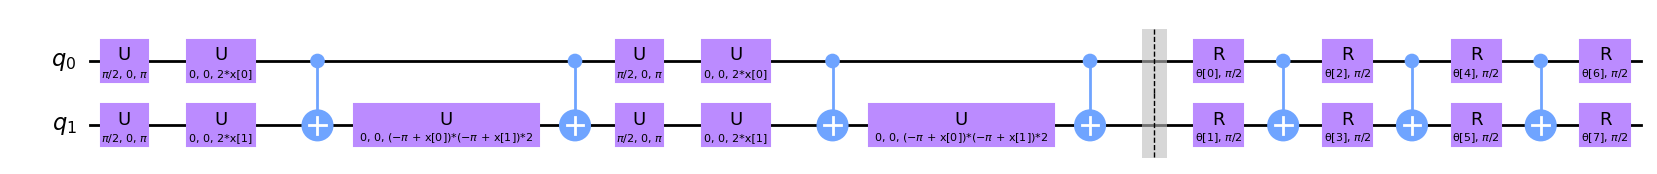

In [ ]:
# Build the Quantum Feature Map and Variational Ansatz using Qiskit 2.x functional builders
feature_map = zz_feature_map(feature_dimension=num_inputs, reps=2, entanglement="full")
ansatz = real_amplitudes(num_qubits=num_inputs, entanglement="full", reps=3)

# Compose into a single Parameterized Quantum Circuit (PQC)
qc = QuantumCircuit(num_inputs)
qc.compose(feature_map, inplace=True)
qc.barrier()
qc.compose(ansatz, inplace=True)

print(f"Qubits             : {qc.num_qubits}")
print(f"Input parameters   : {len(feature_map.parameters)} -> {list(feature_map.parameters)}")
print(f"Trainable weights  : {len(ansatz.parameters)} -> {list(ansatz.parameters)}")

# Draw the decomposed circuit so beginners can inspect the actual H, P, RY, and CX gates
qc.decompose().draw(output="mpl", style="clifford")

## Step 2: Connect the Circuit to PyTorch via `EstimatorQNN`

In Qiskit 2.x, **`StatevectorEstimator`** computes the exact quantum expectation value of a Pauli observable (by default, $O = Z^{\otimes n} = Z \otimes Z$):

$$f(\mathbf{x}; \boldsymbol{\theta}) = \langle \psi(\mathbf{x}, \boldsymbol{\theta}) | Z \otimes Z | \psi(\mathbf{x}, \boldsymbol{\theta}) \rangle \in [-1, 1]$$

### 🔄 How Does PyTorch Differentiate a Quantum Circuit? (The Parameter-Shift Rule)
Classical neural networks use the chain rule through matrix multiplications. For quantum gates of the form $R(\theta) = e^{-i \frac{\theta}{2} P}$, `ParamShiftEstimatorGradient` computes the **exact analytical derivative** by running the circuit twice with shifted angles $\pm \frac{\pi}{2}$:

$$\frac{\partial \langle O \rangle}{\partial \theta_i} = \frac{1}{2} \left[ \langle O \rangle_{\theta_i + \frac{\pi}{2}} - \langle O \rangle_{\theta_i - \frac{\pi}{2}} \right]$$

`TorchConnector` wraps `EstimatorQNN` as a native `torch.nn.Module`, allowing seamless integration with PyTorch optimizers (`Adam`, `LBFGS`) and loss functions.

In [ ]:
# Instantiate Qiskit V2 StatevectorEstimator and analytical Parameter-Shift Gradient
estimator = StatevectorEstimator()
estimator_gradient = ParamShiftEstimatorGradient(estimator=estimator)

# Create the EstimatorQNN
qnn1 = EstimatorQNN(
    circuit=qc,
    input_params=feature_map.parameters,
    weight_params=ansatz.parameters,
    estimator=estimator,
    gradient=estimator_gradient,
)

# Wrap QNN as a PyTorch module with small initial weights
initial_weights = 0.1 * (2 * algorithm_globals.random.random(qnn1.num_weights) - 1)
model1 = TorchConnector(qnn1, initial_weights=initial_weights)

print("Initial trainable weights:", np.round(initial_weights, 4))

# Test a single forward pass on the first customer
sample_output = model1(X_[0, :])
print(f"Sample customer 0 features: {X_[0, :].tolist()} -> Raw QNN output: {sample_output.item():.4f}")

Initial trainable weights: [-0.0126  0.0665  0.0401 -0.0375  0.0665  0.061  -0.0225 -0.0423]
Sample customer 0 features: [0.5479121208190918, -0.12224312126636505] -> Raw QNN output: -0.3320


## Step 3: Loss Function & Hybrid Training Loop

> **Why `MSELoss` instead of `CrossEntropyLoss` here?**  
> `CrossEntropyLoss` expects multi-class logits or probabilities in $[0, 1]$. Because `EstimatorQNN` outputs a single continuous expectation value $\hat{y} \in [-1, 1]$ matching our target labels $y \in \{-1, +1\}$, **Mean Squared Error (`MSELoss`)** directly pushes approved loans toward $+1$ and rejected loans toward $-1$.

We train `model1` using PyTorch's **`LBFGS`** quasi-Newton optimizer and record the loss at every evaluation step so we can visualize convergence.

Initial Loss: 25.4781 -> Final Loss: 14.8868


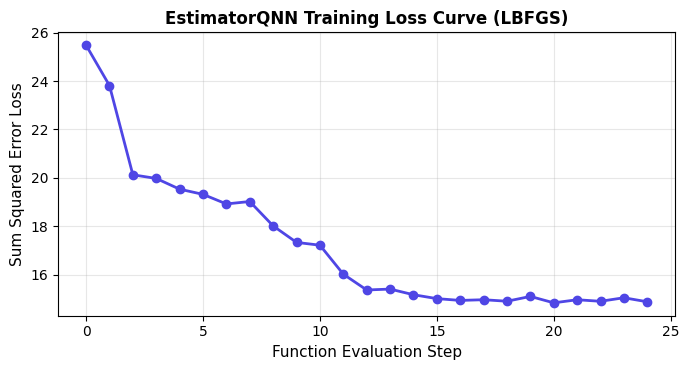

In [ ]:
# Define optimizer and loss function
optimizer = LBFGS(model1.parameters(), max_iter=25, lr=0.5)
f_loss = MSELoss(reduction="sum")

loss_history_est = []
model1.train()

# LBFGS requires a closure that clears gradients, computes loss, and runs backward()
def closure():
    optimizer.zero_grad()
    output = model1(X_)
    loss = f_loss(output, y_)
    loss.backward()
    loss_history_est.append(loss.item())
    return loss

optimizer.step(closure)
print(f"Initial Loss: {loss_history_est[0]:.4f} -> Final Loss: {loss_history_est[-1]:.4f}")

# Plot Training Convergence
plt.figure(figsize=(7, 3.8))
plt.plot(loss_history_est, marker="o", color="#4f46e5", linewidth=2)
plt.title("EstimatorQNN Training Loss Curve (LBFGS)", fontsize=12, fontweight="bold")
plt.xlabel("Function Evaluation Step", fontsize=11)
plt.ylabel("Sum Squared Error Loss", fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Step 4: Evaluate `EstimatorQNN` & Test a New Loan Applicant

We switch the PyTorch model to `.eval()` mode, take the sign of the expectation value $\text{sign}(\hat{y}) \in \{-1, +1\}$ as our predicted decision, and highlight any misclassified applicants with a red ring.

EstimatorQNN Classification Accuracy: 40.0%


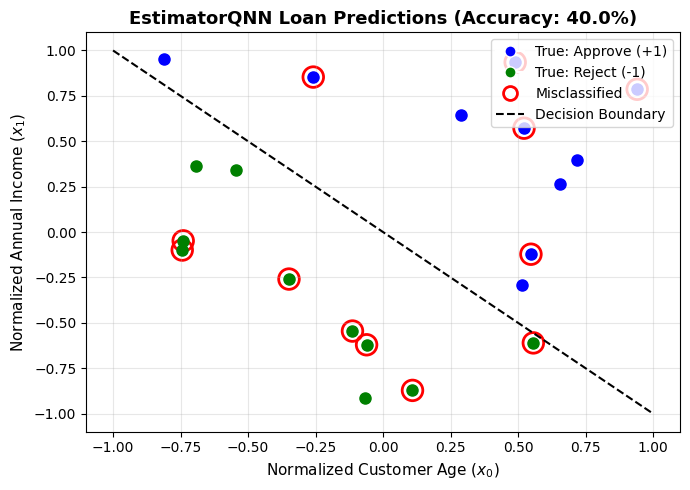

New Applicant [Age=0.45, Income=0.30] -> Score: -0.5953 -> Loan REJECTED (-1)


In [ ]:
model1.eval()
with torch.no_grad():
    raw_preds = model1(X_).numpy().flatten()
    y_predict = np.sign(raw_preds)
    # Handle exact 0 edge case
    y_predict[y_predict == 0] = 1

accuracy_est = np.mean(y_predict == y)
print(f"EstimatorQNN Classification Accuracy: {accuracy_est * 100:.1f}%")

# Plot Classification Results
plt.figure(figsize=(7, 5))
for x_pt, y_target, y_p in zip(X, y, y_predict):
    if y_target == 1:
        plt.plot(x_pt[0], x_pt[1], "bo", markersize=8)
    else:
        plt.plot(x_pt[0], x_pt[1], "go", markersize=8)
    if y_target != y_p:
        plt.scatter(x_pt[0], x_pt[1], s=220, facecolors="none", edgecolors="r", linewidths=2)

plt.plot([-1, 1], [1, -1], "--", color="black", linewidth=1.5)

legend_elements = [
    Line2D([0], [0], marker="o", color="w", label="True: Approve (+1)", markerfacecolor="b", markersize=8),
    Line2D([0], [0], marker="o", color="w", label="True: Reject (-1)", markerfacecolor="g", markersize=8),
    Line2D([0], [0], marker="o", color="w", label="Misclassified", markerfacecolor="none", markeredgecolor="r", markeredgewidth=2, markersize=10),
    Line2D([0], [0], color="black", linestyle="--", label="Decision Boundary"),
]
plt.title(f"EstimatorQNN Loan Predictions (Accuracy: {accuracy_est * 100:.1f}%)", fontsize=13, fontweight="bold")
plt.xlabel("Normalized Customer Age ($x_0$)", fontsize=11)
plt.ylabel("Normalized Annual Income ($x_1$)", fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend(handles=legend_elements, loc="upper right")
plt.tight_layout()
plt.show()

# Live Demo: Predict Loan Approval for a New Applicant
new_applicant = Tensor([[0.45, 0.30]])  # Older + Above-average income
with torch.no_grad():
    score = model1(new_applicant).item()
decision = "APPROVED (+1)" if score >= 0 else "REJECTED (-1)"
print(f"New Applicant [Age=0.45, Income=0.30] -> Score: {score:+.4f} -> Loan {decision}")

# 1.2 Classification with PyTorch and `SamplerQNN`

Unlike `EstimatorQNN` (which computes expectation values of observables), **`SamplerQNN`** runs the quantum circuit using **`StatevectorSampler`** and samples measurement bitstrings (`00`, `01`, `10`, `11`).

### 🎲 Visual Comparison: `EstimatorQNN` vs. `SamplerQNN`

<div align="center">
<svg width="800" height="205" viewBox="0 0 800 205" xmlns="http://www.w3.org/2000/svg">
  <rect x="5" y="5" width="790" height="195" rx="12" fill="#f8fafc" stroke="#cbd5e1" stroke-width="1.5"/>

  <!-- Top Row: EstimatorQNN -->
  <rect x="20" y="22" width="160" height="68" rx="8" fill="#e0e7ff" stroke="#4f46e5" stroke-width="2"/>
  <text x="100" y="52" font-family="sans-serif" font-size="13" font-weight="bold" fill="#1e1b4b" text-anchor="middle">EstimatorQNN</text>
  <text x="100" y="72" font-family="sans-serif" font-size="11" fill="#3730a3" text-anchor="middle">StatevectorEstimator</text>

  <line x1="180" y1="56" x2="230" y2="56" stroke="#4f46e5" stroke-width="2"/>
  <rect x="235" y="22" width="260" height="68" rx="8" fill="#eff6ff" stroke="#2563eb" stroke-width="1.5"/>
  <text x="365" y="50" font-family="sans-serif" font-size="12" font-weight="bold" fill="#1e3a8a" text-anchor="middle">Expectation Value ⟨Z ⊗ Z⟩</text>
  <text x="365" y="70" font-family="monospace" font-size="11" fill="#1d4ed8" text-anchor="middle">Scalar output ∈ [-1, +1]</text>

  <line x1="495" y1="56" x2="545" y2="56" stroke="#4f46e5" stroke-width="2"/>
  <rect x="550" y="22" width="225" height="68" rx="8" fill="#f0fdf4" stroke="#16a34a" stroke-width="1.5"/>
  <text x="662" y="50" font-family="sans-serif" font-size="12" font-weight="bold" fill="#14532d" text-anchor="middle">MSELoss + sign(ŷ)</text>
  <text x="662" y="70" font-family="sans-serif" font-size="11" fill="#15803d" text-anchor="middle">Best for regression &amp; ±1 labels</text>

  <!-- Bottom Row: SamplerQNN -->
  <rect x="20" y="112" width="160" height="68" rx="8" fill="#fae8ff" stroke="#a21caf" stroke-width="2"/>
  <text x="100" y="142" font-family="sans-serif" font-size="13" font-weight="bold" fill="#701a75" text-anchor="middle">SamplerQNN</text>
  <text x="100" y="162" font-family="sans-serif" font-size="11" fill="#86198f" text-anchor="middle">StatevectorSampler</text>

  <line x1="180" y1="146" x2="230" y2="146" stroke="#a21caf" stroke-width="2"/>
  <rect x="235" y="112" width="260" height="68" rx="8" fill="#fdf4ff" stroke="#c026d3" stroke-width="1.5"/>
  <text x="365" y="140" font-family="sans-serif" font-size="12" font-weight="bold" fill="#701a75" text-anchor="middle">Parity Interpret Function</text>
  <text x="365" y="160" font-family="monospace" font-size="11" fill="#86198f" text-anchor="middle">P(even)={00,11}, P(odd)={01,10}</text>

  <line x1="495" y1="146" x2="545" y2="146" stroke="#a21caf" stroke-width="2"/>
  <rect x="550" y="112" width="225" height="68" rx="8" fill="#fff1f2" stroke="#e11d48" stroke-width="1.5"/>
  <text x="662" y="140" font-family="sans-serif" font-size="12" font-weight="bold" fill="#881337" text-anchor="middle">CrossEntropyLoss + argmax</text>
  <text x="662" y="160" font-family="sans-serif" font-size="11" fill="#9f1239" text-anchor="middle">Outputs class probabilities [0, 1]</text>
</svg>
</div>

### 🔢 How the Parity Post-Processing Works
A 2-qubit measurement produces $2^2 = 4$ possible bitstrings. We define a custom **`parity`** function that counts the number of `1`s in the bitstring modulo 2:
* **Even parity (`0`):** bitstrings `00` ($0$) and `11` ($3$) $\rightarrow$ summed into $P(\text{Reject Loan})$
* **Odd parity (`1`):** bitstrings `01` ($1$) and `10` ($2$) $\rightarrow$ summed into $P(\text{Approve Loan})$

Because `SamplerQNN` outputs valid probabilities $[P(y=0), P(y=1)] \in [0, 1]^2$, we can train it directly with **`CrossEntropyLoss`**!

In [ ]:
# Define feature map and ansatz for SamplerQNN
feature_map_s = zz_feature_map(feature_dimension=num_inputs, reps=2, entanglement="full")
ansatz_s = real_amplitudes(num_qubits=num_inputs, entanglement="linear", reps=2)

qc_s = QuantumCircuit(num_inputs)
qc_s.compose(feature_map_s, inplace=True)
qc_s.compose(ansatz_s, inplace=True)

# Instantiate Qiskit V2 StatevectorSampler and Parameter-Shift Sampler Gradient
sampler = StatevectorSampler()
sampler_gradient = ParamShiftSamplerGradient(sampler=sampler)

# Parity interpret function maps integer bitstrings (0..3) to class {0, 1}
parity = lambda x: f"{x:b}".count("1") % 2
output_shape = 2  # Two classes: 0 (Reject) and 1 (Approve)

qnn2 = SamplerQNN(
    circuit=qc_s,
    input_params=feature_map_s.parameters,
    weight_params=ansatz_s.parameters,
    interpret=parity,
    output_shape=output_shape,
    sampler=sampler,
    gradient=sampler_gradient,
)

initial_weights_s = 0.1 * (2 * algorithm_globals.random.random(qnn2.num_weights) - 1)
model2 = TorchConnector(qnn2, initial_weights=initial_weights_s)

# Train using LBFGS and CrossEntropyLoss
optimizer_s = LBFGS(model2.parameters(), max_iter=25, lr=0.5)
f_loss_s = CrossEntropyLoss()

loss_history_samp = []
model2.train()

def closure_s():
    optimizer_s.zero_grad(set_to_none=True)
    probs = model2(X_)
    loss = f_loss_s(probs, y01_)
    loss.backward()
    loss_history_samp.append(loss.item())
    return loss

optimizer_s.step(closure_s)

# Evaluate SamplerQNN
model2.eval()
with torch.no_grad():
    y_predict_s = np.argmax(model2(X_).numpy(), axis=1)

accuracy_samp = np.mean(y_predict_s == y01)
print(f"SamplerQNN Classification Accuracy: {accuracy_samp * 100:.1f}%")

# Side-by-side plot: Loss Curve & Classification Result
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(loss_history_samp, marker="s", color="#a21caf", linewidth=2)
axes[0].set_title("SamplerQNN Training Loss (Cross-Entropy)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Function Evaluation Step", fontsize=11)
axes[0].set_ylabel("Cross-Entropy Loss", fontsize=11)
axes[0].grid(True, alpha=0.3)

for x_pt, y_target, y_p in zip(X, y01, y_predict_s):
    if y_target == 1:
        axes[1].plot(x_pt[0], x_pt[1], "bo", markersize=8)
    else:
        axes[1].plot(x_pt[0], x_pt[1], "go", markersize=8)
    if y_target != y_p:
        axes[1].scatter(x_pt[0], x_pt[1], s=220, facecolors="none", edgecolors="r", linewidths=2)

axes[1].plot([-1, 1], [1, -1], "--", color="black", linewidth=1.5)
axes[1].set_title(f"SamplerQNN Loan Predictions (Accuracy: {accuracy_samp * 100:.1f}%)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Normalized Customer Age ($x_0$)", fontsize=11)
axes[1].set_ylabel("Normalized Annual Income ($x_1$)", fontsize=11)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 2. Regression: Modeling a Cyclical Financial Yield Curve

Beyond binary classification, Quantum Neural Networks naturally represent smooth trigonometric functions because single-qubit rotation gates $R_Y(\theta)$ and $R_Z(\theta)$ evolve state amplitudes via $\cos(\theta/2)$ and $\sin(\theta/2)$.

### 📈 Task
We generate noisy samples from a cyclical financial yield/rate trend:
$$y = \sin(x) + \epsilon, \quad x \in [-\pi, \pi]$$
and train a **1-qubit `EstimatorQNN`** with `MSELoss` to recover the underlying curve.

# 🎓 Summary & Qiskit Fall Fest Audience Challenges

### Key Takeaways
| Concept | Modern Qiskit 2.x Implementation | Takeaway |
| :--- | :--- | :--- |
| **Circuit Library** | `zz_feature_map(...)`, `real_amplitudes(...)` | Functional builders construct lightweight `QuantumCircuit` objects directly. |
| **Qiskit V2 Primitives** | `StatevectorEstimator`, `StatevectorSampler` | Standard interfaces for expectation values and bitstring sampling across simulators and IBM Quantum QPUs. |
| **Quantum Gradients** | `ParamShiftEstimatorGradient`, `ParamShiftSamplerGradient` | Computes hardware-compatible analytical derivatives via $\pm \frac{\pi}{2}$ parameter shifts. |
| **Hybrid Integration** | `TorchConnector(qnn)` | Turns any Qiskit QNN into a differentiable PyTorch layer (`nn.Module`). |

### 🚀 Hands-On Challenges for Attendees
1. **Circuit Expressivity:** Increase `reps=3` in `zz_feature_map` or change `entanglement="circular"`—how does it affect convergence speed and accuracy?
2. **True Hybrid Architecture:** Prepend a classical PyTorch `nn.Linear(4, 2)` layer before `TorchConnector(qnn1)` so the network can compress **4 financial features** (Age, Income, Debt Ratio, Credit History) onto a **2-qubit quantum processor**!
3. **Noise & Hardware Readiness:** Swap `StatevectorEstimator` for `qiskit_ibm_runtime.EstimatorV2` with a preset `pass_manager` to test how hardware noise impacts decision boundaries.

In [ ]:
from qiskit.circuit import Parameter

# Generate noisy cyclical financial trend data in [-pi, pi]
num_reg_samples = 25
eps = 0.15
lb, ub = -np.pi, np.pi

X_reg = (ub - lb) * algorithm_globals.random.random([num_reg_samples, 1]) + lb
y_reg = np.sin(X_reg[:, 0]) + eps * (2 * algorithm_globals.random.random(num_reg_samples) - 1)

X_reg_ = Tensor(X_reg)
y_reg_ = Tensor(y_reg).reshape(num_reg_samples, 1)

# Build a compact 1-qubit Quantum Neural Network for Regression
param_x = Parameter("x")
param_w = Parameter("w")

qc_reg = QuantumCircuit(1)
qc_reg.ry(param_x, 0)  # Encode scalar input x
qc_reg.rx(param_w, 0)  # Trainable rotation weight w

estimator_reg = StatevectorEstimator()
qnn3 = EstimatorQNN(
    circuit=qc_reg,
    input_params=[param_x],
    weight_params=[param_w],
    estimator=estimator_reg,
    gradient=ParamShiftEstimatorGradient(estimator=estimator_reg),
)

initial_weights_reg = 0.1 * (2 * algorithm_globals.random.random(qnn3.num_weights) - 1)
model3 = TorchConnector(qnn3, initial_weights=initial_weights_reg)

# Train Regressor with LBFGS and MSELoss
optimizer_reg = LBFGS(model3.parameters(), max_iter=20)
f_loss_reg = MSELoss(reduction="sum")

model3.train()
def closure_reg():
    optimizer_reg.zero_grad()
    loss = f_loss_reg(model3(X_reg_), y_reg_)
    loss.backward()
    return loss

optimizer_reg.step(closure_reg)

# Plot True Function, Noisy Observations, and Quantum Regression Fit
model3.eval()
x_grid = np.linspace(lb, ub, 100)
with torch.no_grad():
    y_grid_pred = model3(Tensor(x_grid.reshape(-1, 1))).numpy().flatten()

plt.figure(figsize=(8, 4.5))
plt.plot(x_grid, np.sin(x_grid), "r--", linewidth=2, label="True Yield Trend: $\sin(x)$")
plt.scatter(X_reg, y_reg, color="#0f172a", alpha=0.75, label="Noisy Market Samples")
plt.plot(x_grid, y_grid_pred, color="#2563eb", linewidth=2.5, label="EstimatorQNN Fit")
plt.title("1-Qubit Quantum Neural Network Regression", fontsize=13, fontweight="bold")
plt.xlabel("Normalized Time Horizon ($x$)", fontsize=11)
plt.ylabel("Normalized Yield Spread ($y$)", fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()